# Description

- Train a DQN agent with RLlib to sell 100,000 SPY shares in 20 steps
  within one trading day, minimizing the implementation shortfall (bps)
  versus the arrival price
- Calibrate the simulated market on NYSE TAQ 2015-2019 and test on paths
  calibrated on 2020-2024, split by calm and stressed VIX regimes
- Compare the agent with TWAP and with selling everything at once

- References:
  - Spec: `RLlib_Project_Description.md`, Project 1
  - Almgren and Chriss (2000), "Optimal Execution of Portfolio Transactions"
  - Almgren, Thum, Hauptmann, and Li (2005), "Direct Estimation of Equity
    Market Impact"
  - RLlib: https://docs.ray.io/en/latest/rllib/index.html

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

# System libraries.
import logging
from typing import Any, Callable, Dict, Tuple

# Third-party libraries.
import numpy as np
import pandas as pd
import ray

In [2]:
import helpers.hnotebook as hnotebook

import class_project.msml610.Fall2026.projects.UmdTask686_MSML610_Fall2026_RLlib.data_utils as rldautil
import class_project.msml610.Fall2026.projects.UmdTask686_MSML610_Fall2026_RLlib.rllib_utils as rlutils
import class_project.msml610.Fall2026.projects.UmdTask686_MSML610_Fall2026_RLlib.taq_utils as rltautil

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
rlutils.init_loggers(_LOG)

# Use IPython `display()` in Jupyter and fall back to `print()` otherwise.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpyvvuvnf0.json --HistoryManager.hist_file=:memory:


## Calibrate the Market

- Train: one calibration on all the 2015-2019 days
- Test: one calibration per VIX regime on the 2020-2024 days
  - A day is `calm` if the previous VIX close is below 20, otherwise
    `stressed`
- The 1,000 test episodes are split between the regimes in proportion to
  their days
- Only summary statistics are shown; the TAQ bars stay local

In [3]:
total_shares = rlutils.DEFAULT_CONFIG["total_shares"]
n_steps = rlutils.DEFAULT_CONFIG["n_steps"]
train_params = rldautil.calibrate(
    rltautil.load_spy_taq(2015, 2019), n_steps, total_shares
)
vix = rldautil.load_vix()
test_params = rldautil.calibrate_by_regime(
    rltautil.load_spy_taq(2020, 2024), vix, n_steps, total_shares
)
params = {"train 2015-2019": train_params}
params.update({f"test {k}": v for k, v in test_params.items()})
keys = ["n_days", "daily_vol", "adv", "half_spread_bps", "gamma", "eta"]
display(pd.DataFrame(params).loc[keys])

,train 2015-2019,test calm,test stressed
n_days,1.258000e+03,6.530000e+02,6.050000e+02
daily_vol,6.776973e-03,6.031410e-03,1.199997e-02
adv,7.344646e+07,5.422005e+07,7.948360e+07
half_spread_bps,2.681420e-01,1.274305e-01,2.170579e-01
gamma,2.127969e-03,1.893863e-03,3.767990e-03
eta,1.924660e-02,1.712921e-02,3.407991e-02


In [4]:
action = {"action_type": "twap_multiple"}
train_config = {**rldautil.to_env_config(train_params), **action}
test_configs = {
    k: {**rldautil.to_env_config(v), **action} for k, v in test_params.items()
}
n_test = 1000
n_days = {k: v["n_days"] for k, v in test_params.items()}
n_calm = round(n_test * n_days["calm"] / sum(n_days.values()))
regime_episodes = {"calm": n_calm, "stressed": n_test - n_calm}
print("test episodes:", regime_episodes)

test episodes: {'calm': 519, 'stressed': 481}


## Evaluate on the Test Regimes

- Every policy runs on the same 1,000 test paths, so the win rate compares
  each policy with TWAP episode by episode
- All costs are in bps of the arrival value:
  - `shortfall`: the true implementation shortfall, with the price noise
  - `expected cost`: the same without the P&L of the price noise on the
    shares still held, which compares the schedules precisely

In [5]:
def evaluate(
    policies: Dict[str, Callable],
    regime_configs: Dict[str, Dict[str, Any]],
    episodes: Dict[str, int],
) -> Tuple[pd.DataFrame, Dict[str, np.ndarray]]:
    """
    Run each policy on the test paths and summarize them by regime.

    :param policies: policy name to policy for `rlutils.run_episodes()`
    :param regime_configs: regime name to environment config
    :param episodes: regime name to number of episodes
    :return: summary with one row per regime and policy, and the inventory
        paths of all the episodes of each policy
    """
    # Use the same seeds for every policy, away from the training seeds.
    seed = 10_000
    results = {
        name: rlutils.run_by_regime(policy, regime_configs, episodes, seed=seed)
        for name, policy in policies.items()
    }
    tables = {}
    for regime in list(episodes) + ["all"]:
        regimes = list(episodes) if regime == "all" else [regime]
        costs = {
            name: pd.concat([res[r][0] for r in regimes], ignore_index=True)
            for name, res in results.items()
        }
        tables[regime] = rlutils.summarize_episodes(costs)
    summary = pd.concat(tables, names=["regime", "policy"])
    inventory = {
        name: np.concatenate([res[r][1] for r in episodes])
        for name, res in results.items()
    }
    return summary, inventory


baselines = {
    "TWAP": lambda env, obs: rlutils.twap_shares(env),
    "sell-all": lambda env, obs: rlutils.sell_all_shares(env),
}
baseline_summary, baseline_inventory = evaluate(
    baselines, test_configs, regime_episodes
)
display(baseline_summary.round(3))

shortfall mean  shortfall std  expected cost  win rate vs TWAP
regime   policy                                                                  
calm     TWAP               0.909         34.458          0.160             0.000
         sell-all           0.443          0.000          0.443             0.493
stressed TWAP               2.498         68.338          0.261             0.000
         sell-all           0.646          0.000          0.646             0.495
all      TWAP               1.673         53.509          0.208             0.000
         sell-all           0.541          0.101          0.541             0.494

## Train the Agent

- `rlutils.train_dqn()` registers `ExecutionEnv` with `register_env`,
  configures `DQNConfig` with 2 env runners, and calls `Algorithm.train()`
  60 times (~60,000 env steps, ~3,000 episodes)
- Each action sells a multiple (0 to 3x) of the TWAP pace, the remaining
  inventory over the remaining steps, so TWAP is the action 1.0 at every step
- Two agents differ only in the reward:
  - `shortfall`: the spec reward, the negative shortfall of each step
  - `expected_cost`: the same reward minus the P&L of the price shock on
    the shares still held, which has zero mean whatever the agent does
- Both rewards have the same expected episode return, but the price noise
  (~38 bps std per episode) is ~100x the cost differences between schedules
  (<1 bp), so the `shortfall` reward is mostly noise
- Training varies from run to run, so each agent is trained with 3 seeds
  and the results average over them
  - Each trained agent is evaluated on the test paths right away, then
    stopped to free the CPUs of its env runners

In [6]:
def train_and_evaluate(
    name: str,
    env_config: Dict[str, Any],
    regime_configs: Dict[str, Dict[str, Any]],
    seeds: Tuple[int, ...] = (0, 1, 2),
) -> Tuple[pd.DataFrame, np.ndarray, Dict[str, pd.DataFrame]]:
    """
    Train one DQN agent per seed and evaluate each one on the test paths.

    :param name: name of the agent in the summary
    :param env_config: training environment config
    :param regime_configs: regime name to test environment config
    :param seeds: training seeds
    :return: summary rows of the agent averaged over the seeds, with the std
        of the expected cost across seeds; inventory paths of all the seeds;
        learning curve of each seed
    """
    rows = []
    paths = []
    curves = {}
    for seed in seeds:
        algo, curves[f"seed {seed}"] = rlutils.train_dqn(env_config, seed=seed)
        policy = rlutils.get_greedy_policy(algo.get_module())
        summary, inventory = evaluate(
            {**baselines, name: policy}, regime_configs, regime_episodes
        )
        algo.stop()
        rows.append(summary.xs(name, level="policy"))
        paths.append(inventory[name])
    grouped = pd.concat(rows).groupby(level=0, sort=False)
    agent = grouped.mean()
    agent["expected cost std over seeds"] = grouped["expected cost"].std()
    agent.index = pd.MultiIndex.from_product(
        [agent.index, [name]], names=["regime", "policy"]
    )
    return agent, np.concatenate(paths), curves


# Start Ray with 4 CPUs: 1 for the driver and learner, 2 for env runners.
ray.init(num_cpus=4, include_dashboard=False, log_to_driver=False)
agent_rows = []
inventory = dict(baseline_inventory)
curves = {}
for reward in ("shortfall", "expected_cost"):
    name = f"DQN ({reward})"
    env_config = {**train_config, "reward": reward}
    rows, inventory[name], curves[name] = train_and_evaluate(
        name, env_config, test_configs
    )
    agent_rows.append(rows)

2026-11-16 03:01:00,496	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


2026-11-16 03:01:00,497	INFO authentication_token_setup.py:50 -- Generated new authentication token and saved to /root/.ray/auth_token


2026-11-16 03:01:06,732	INFO worker.py:2033 -- Started a local Ray instance.


2026-11-16 03:01:12,051	WARNING algorithm_config.py:5160 -- You are running DQN on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html


[2026-11-16 03:01:13,426 E 9 9] core_worker.cc:2297: Actor with class name: 'SingleAgentEnvRunner' and ID: '7ecebd74fe9ce2df1d3dccf601000000' has constructor arguments in the object store and max_restarts > 0. If the arguments in the object store go out of scope or are lost, the actor restart will fail. See https://github.com/ray-project/ray/issues/53727 for more details.


2026-11-16 03:01:19,219	WARNING rl_module.py:463 -- DeprecationWarning: `RLModule(config=[RLModuleConfig object])` has been deprecated. Use `RLModule(observation_space=.., action_space=.., inference_only=.., model_config=.., catalog_class=..)` instead. This will raise an error in the future!


... (363 outputs left out)

{'iteration': 57, 'episode_return_mean': np.float64(-0.3214696427140541), 'env_steps': 57000.0, 'time_s': 171.66151595115662}


{'iteration': 58, 'episode_return_mean': np.float64(-0.3342723364617182), 'env_steps': 58000.0, 'time_s': 174.22174406051636}


{'iteration': 59, 'episode_return_mean': np.float64(-0.3218442030418353), 'env_steps': 59000.0, 'time_s': 177.52297568321228}


{'iteration': 60, 'episode_return_mean': np.float64(-0.32425699078933834), 'env_steps': 60000.0, 'time_s': 180.1750078201294}


### Learning Curves

- Mean episode return per training iteration, including the exploration
  episodes
- One plot per agent, with one line per seed, since the `shortfall` curve
  is ~100x noisier

DQN (shortfall)


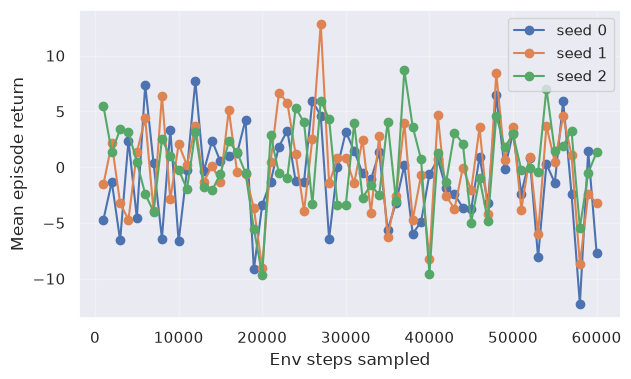

DQN (expected_cost)


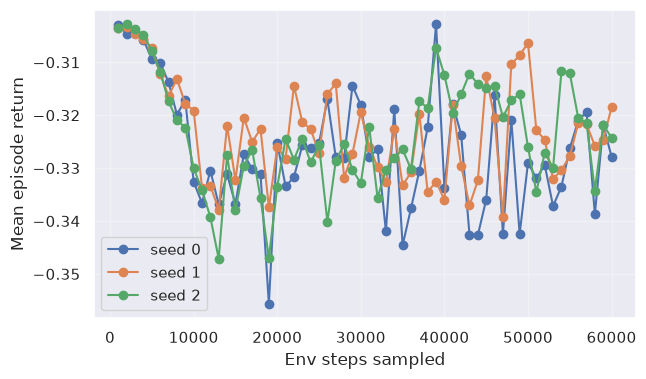

In [7]:
for name, seed_curves in curves.items():
    print(name)
    rlutils.plot_learning_curves(seed_curves)

## Evaluate the Policy

- Mean and std of the shortfall, mean expected cost, and win rate against
  TWAP over the 1,000 test episodes, split by VIX regime
- The DQN rows average the 3 seeds; `expected cost std over seeds` shows
  how much the expected cost changes from one training run to the next
- A policy can win more than half the episodes against TWAP and still cost
  more on average, so compare the expected cost, not only the win rate

In [8]:
regimes = list(regime_episodes) + ["all"]
summary = pd.concat([baseline_summary] + agent_rows).loc[regimes]
display(summary.round(3))

shortfall mean  shortfall std  expected cost  win rate vs TWAP  expected cost std over seeds
regime   policy                                                                                                           
calm     TWAP                          0.909         34.458          0.160             0.000                           NaN
         sell-all                      0.443          0.000          0.443             0.493                           NaN
         DQN (shortfall)               0.533         24.359          0.173             0.559                         0.003
         DQN (expected_cost)           0.879         33.065          0.198             0.554                         0.011
stressed TWAP                          2.498         68.338          0.261             0.000                           NaN
         sell-all                      0.646          0.000          0.646             0.495                           NaN
         DQN (shortfall)               1.510         47.910          0.279             0.577                         0.005
         DQN (expected_cost)           1.125         62.699          0.314             0.572                         0.015
all      TWAP                          1.673         53.509          0.208             0.000                           NaN
         sell-all                      0.541          0.101          0.541             0.494                           NaN
         DQN (shortfall)               1.003         37.581          0.224             0.568                         0.004
         DQN (expected_cost)           0.997         49.583          0.254             0.562                         0.013

## Visualize the Policy

- Average fraction of the inventory left at each step, over all the test
  episodes and, for the agents, all the seeds

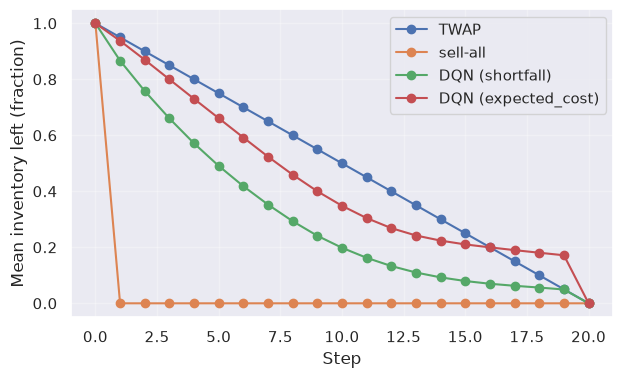

In [9]:
rlutils.plot_inventory(inventory)

## Order Size Sweep

- 100,000 shares is ~0.14% of SPY's daily volume, so impact is small
- Larger orders, as a percentage of the 2015-2019 ADV, make the schedule
  matter more
- Train 3 `expected_cost` agents per size, one per seed, then evaluate
  them on the test paths

In [10]:
rows = {}
for pct_adv in (1.0, 5.0, 10.0):
    shares = round(pct_adv / 100 * train_config["adv"])
    env_config = {
        **train_config,
        "total_shares": shares,
        "reward": "expected_cost",
    }
    configs = {
        k: {**v, "total_shares": shares} for k, v in test_configs.items()
    }
    summary_base, _ = evaluate(baselines, configs, regime_episodes)
    summary_agent, _, _ = train_and_evaluate(
        "DQN (expected_cost)", env_config, configs
    )
    summary_size = pd.concat([summary_base, summary_agent])
    label = f"{pct_adv:.0f}% ADV ({shares / 1e6:.2f}M shares)"
    rows[label] = summary_size.loc["all"]
sweep = pd.concat(rows, names=["order", "policy"])
display(sweep.round(3))

2026-11-16 03:25:41,637	INFO trainable.py:154 -- Trainable.setup took 10.118 seconds. If your trainable is slow to initialize, consider setting reuse_actors=True to reduce actor creation overheads.


2026-11-16 03:25:41,640	WARNING util.py:62 -- Install gputil for GPU system monitoring.


{'iteration': 1, 'episode_return_mean': np.float64(-0.5243920659374952), 'env_steps': 1000.0, 'time_s': 1.4829742908477783}


{'iteration': 2, 'episode_return_mean': np.float64(-0.536030749861459), 'env_steps': 2000.0, 'time_s': 2.7633211612701416}


{'iteration': 3, 'episode_return_mean': np.float64(-0.5162231523535992), 'env_steps': 3000.0, 'time_s': 6.039958715438843}


{'iteration': 4, 'episode_return_mean': np.float64(-0.5297970013716494), 'env_steps': 4000.0, 'time_s': 9.89723515510559}


... (542 outputs left out)

{'iteration': 58, 'episode_return_mean': np.float64(-3.621194692478673), 'env_steps': 58000.0, 'time_s': 172.2929573059082}


{'iteration': 59, 'episode_return_mean': np.float64(-3.390265899363527), 'env_steps': 59000.0, 'time_s': 174.6613039970398}


{'iteration': 60, 'episode_return_mean': np.float64(-3.4232823429640833), 'env_steps': 60000.0, 'time_s': 177.08607125282288}


shortfall mean  shortfall std  expected cost  win rate vs TWAP  expected cost std over seeds
order                  policy                                                                                                           
1% ADV (0.73M shares)  TWAP                          1.914         53.508          0.449             0.000                           NaN
                       sell-all                      2.890          0.459          2.890             0.477                           NaN
                       DQN (expected_cost)           1.799         48.214          0.760             0.541                         0.172
5% ADV (3.67M shares)  TWAP                          3.028         53.503          1.564             0.000                           NaN
                       sell-all                     13.765          2.115         13.765             0.407                           NaN
                       DQN (expected_cost)           2.927         43.905          2.442             0.534                         0.109
10% ADV (7.34M shares) TWAP                          4.421         53.498          2.957             0.000                           NaN
                       sell-all                     27.360          4.186         27.360             0.336                           NaN
                       DQN (expected_cost)           4.916         42.461          4.596             0.519                         0.327

In [11]:
ray.shutdown()

## Summary

- The market is calibrated on NYSE TAQ: volatility, volume, and spread
  from the data, impact from Almgren et al. (2005)
- With linear impact and no risk penalty, TWAP has the lowest expected
  cost, so an agent can at best match it on average
- The `expected_cost` reward removes the price noise from training without
  changing the objective
- The Almgren-Chriss variance penalty (bonus) is where an agent can beat
  TWAP, since selling earlier lowers the risk